# U-net Architecture Implementation

## Context of this work
This work is an implementation of a U-net architecture, described in the following article : 
- “U-Net: Convolutional Networks for Biomedical Image Segmentation”: https://arxiv.org/abs/1505.04597

Important notions are:
- The **Encoder-Decoder architecture**.
- Types of **convolutions** **(deconvolutions)** and **pooling** that are used. (see about "Transposed Convolutions" : https://d2l.ai/chapter_computer-vision/transposed-conv.html)
- The use of **skip connections**.
- The type of **normalization** that is used in the architecture.
- The **loss** that is considered for training.
- The metrics that are used for the **evaluation**.

## Implementation

### Model Definition

In [2]:
import torch

class UNet(torch.nn.Module):
    def __init__(self):
        super(UNet, self).__init__()

        # --- Contracting Path ---
        self.block1 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=3, out_channels=64, kernel_size=(3,3), stride=1, padding=0),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,3), stride=1, padding=0),
            torch.nn.ReLU()
        )

        self.block2 = torch.nn.Sequential(
            torch.nn.MaxPool2d(kernel_size=(2,2), stride=2),
            torch.nn.Conv2d(in_channels=64, out_channels=128, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=128, out_channels=128, kernel_size=(3,3), stride=1),
            torch.nn.ReLU()
        )

        self.block3 = torch.nn.Sequential(
            torch.nn.MaxPool2d(kernel_size=(2,2), stride=2),
            torch.nn.Conv2d(in_channels=128, out_channels=256, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=256, out_channels=256, kernel_size=(3,3), stride=1),
            torch.nn.ReLU()
        )

        self.block4 = torch.nn.Sequential(
            torch.nn.MaxPool2d(kernel_size=(2,2), stride=2),
            torch.nn.Conv2d(in_channels=256, out_channels=512, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1),
            torch.nn.ReLU()
        )

        # --- Bridge ---
        self.bridge = torch.nn.Sequential(
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Conv2d(in_channels=512, out_channels=1024, kernel_size=(3,3)),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=1024, out_channels=1024, kernel_size=(3,3)),
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(in_channels=1024, out_channels=512, kernel_size=(2,2), stride=2)
        )

        # --- Expansive path ---
        self.block5 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=1024, out_channels=512, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(in_channels=512, out_channels=256, kernel_size=(2,2), stride=2)

        )
        self.block6 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=512, out_channels=256, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=256, out_channels=256, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=(2,2), stride=2)
        )

        self.block7 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=256, out_channels=128, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=128, out_channels=128, kernel_size=(3,3),  stride=1),
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=(2,2), stride=2)
        )

        self.block8 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=128, out_channels=64, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,3), stride=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(in_channels=64, out_channels=3, kernel_size=(1,1), stride=1)
        )


    def center_crop(self, skip, target):
        """
            Crop an image of dim (N, C, H1, W1) to a target dim (N, C, H2, W2)
        """
        _, _, H1, W1 = skip.shape
        _, _, H2, W2 = target.shape
        dh, dw = (H1 - H2) // 2, (W1 - W2) // 2
        return skip[:, :, dh:dh + H2, dw:dw + W2]


    def forward(self, x):
        """
            Input shape,    x : (N, 3, 572, 572)
            Outpuit shape,  y : (N, 2, 388, 388)
        """
        x1 = self.block1(x)                                                                     # x1.shape =        (N, 64, 568, 568)
        x2 = self.block2(x1)                                                                    # x2.shape =        (N, 128, 280, 280)
        x3 = self.block3(x2)                                                                    # x3.shape =        (N, 256, 136, 136)
        x4 = self.block4(x3)                                                                    # x4.shape =        (N, 512, 64, 64)
        xbridge = self.bridge(x4)                                                               # xbridge.shape =   (N, 1024, 28, 28)
        x5 = self.block5(torch.cat((xbridge, self.center_crop(x4, xbridge)), dim=1))            # x5.shape =        (N, 512, 52, 52)
        x6 = self.block6(torch.cat((x5, self.center_crop(x3, x5)), dim=1))                      # x6.shape =        (N, 256, 100, 100)
        x7 = self.block7(torch.cat((x6, self.center_crop(x2, x6)), dim=1))                      # x7.shape =        (N, 128, 194, 194)
        x8 = self.block8(torch.cat((x7, self.center_crop(x1, x7)), dim=1))                      # x8.shape =        (N, 64, 388, 388)

        y = x8 
        return y

Computing the number of parameters and estimate size on disk :

In [3]:
model = UNet()
nb_trainable = 0
nb_non_trainable = 0

for p in model.parameters():
    if p.requires_grad:
        nb_trainable += p.numel()
        continue
    nb_non_trainable += p.numel()

nb_parameters = nb_trainable + nb_non_trainable

print(f"Number of parameters in the model: {nb_trainable} | Number of non trainable parameters: {nb_non_trainable}")

Number of parameters in the model: 31031875 | Number of non trainable parameters: 0


In [4]:
size_on_disk = nb_parameters * 4
print(f"{size_on_disk / 1000000} Mb")

124.1275 Mb


## Dataset definition and loading

We will use the Oxford-IIIT Pet Dataset : https://www.robots.ox.ac.uk/~vgg/data/pets/

This dataset contains :
- [n] train images
- [m] test images
> Each image has variable dimensions.

The labels have same dimensions as the images, but contains 

In [5]:

from pathlib import Path

from torchvision import transforms, tv_tensors
from PIL import Image
from torchvision.transforms import v2

def to_rgb(img):
    return img.convert("RGB")

class Pets(torch.utils.data.Dataset):
    def __init__(self, root, split='trainval', out_size = 388, margin = 92, augment=False):
        root = Path(root)
        self.img_dir = root / "images"
        self.label_dir = root / "annotations" /  "trimaps"
        self.out_size = out_size
        self.margin = margin

        # -- Retrieve the labeled image files names --
        with open(root / "annotations" / f"{split}.txt") as f :
            candidates = [line.split()[0] for line in f
                          if line.strip() and not line.startswith("#")]

        self.names = [n for n in candidates
                      if (self.img_dir / f"{n}.jpg").exists()
                      and (self.label_dir / f"{n}.png").exists()]

        # -- Data augmentation --
        if augment:
            self.augment = v2.Compose([
                v2.RandomHorizontalFlip(),
                v2.RandomResizedCrop((out_size, out_size), scale=(0.5,1.0), antialias=True),
                v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
            ])
        else:
            self.augment= v2.Identity()

        # -- Transforms (applient on top of data augmentation) --
        self.img_transform = v2.Compose([
            v2.Resize((out_size, out_size), antialias=True),
            v2.ToDtype({tv_tensors.Image: torch.float32, tv_tensors.Mask: torch.uint8}, scale=True),  # Scale=True map each pixel to a float in [0, 1] instead of [0, 255]
        ])

    
    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        # -- Retrieve couple (img, label) from file names --
        name = self.names[index]

        img = Image.open(self.img_dir / (name + ".jpg")).convert("RGB")     # to rgb
        label = Image.open(self.label_dir / (name + ".png"))

        img = tv_tensors.Image(v2.functional.pil_to_tensor(img))            # to tensor (3, H, W)
        label = tv_tensors.Mask(v2.functional.pil_to_tensor(label))         # to tensor (1, H, W)

        # -- apply data augmentatiopn --
        img, label = self.augment(img, label)                               # Augment the data, img: (3, x, y), random x and y doisn't matter since we'll resize again

        # -- apply transforms --
        img, label = self.img_transform(img, label)                         # resize  (img: (3, 388, 388)) + to [0, 1]
        img = v2.functional.pad(img, self.margin, padding_mode='reflect')   # padding strategy, (3, 572, 572)

        return img, label




In [6]:
train_set = Pets('oxford', split='trainval', augment=True)
test_set = Pets('oxford', split='test', augment=False)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=1, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1, shuffle=True)

In [7]:
from pathlib import Path
import numpy as np
from PIL import Image

root = Path('oxford')
img_dir = root / "images"
label_dir = root / "annotations" / "trimaps"

with open(root / "annotations" / "trainval.txt") as f:
    candidates = [line.split()[0] for line in f
                  if line.strip() and not line.startswith("#")]

names = [n for n in candidates
         if (img_dir / f"{n}.jpg").exists()
         and (label_dir / f"{n}.png").exists()]

rand_name = names[np.random.randint(len(names))]

rand_img = Image.open(img_dir / f"{rand_name}.jpg")
rand_label = Image.open(label_dir / f"{rand_name}.png")

rand_img_np = np.asarray(rand_img)
rand_label_np = np.asarray(rand_label)

print("image:", rand_img_np.shape, rand_img.mode)
print("label:", rand_label_np.shape, rand_label.mode, np.unique(rand_label_np))

image: (414, 500, 3) RGB
label: (414, 500) L [1 2 3]


In [8]:
import numpy as np
n = np.random.randint(0, 200)
print(train_set[n][0].shape)

torch.Size([3, 572, 572])


## Training loop

### Loss function
We'll use the log loss (log of the cross entropy loss) :

For each class, we have a map of logits $a_k(x)$, with $x$, a pixel in a 388x388 image.
For each class, we want a probability distribution within the image, we will therefore apply the softmax function :
$$
p_k(x) = \frac{exp(a_k(x)))}{\sum_{k=1}^K exp(a_{k'}(x))}
$$

Hence, we can define the loss, in order to quantify the error between the predictions and original labels :
$$
E = \sum_{x \in \Omega} w(x) log(p_{l(x)}(x))
$$

> Note : The original labels will not have to bee cropped. Original pictures have a margin (mirroring) in order to obtain the original image dimensions for the output.

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # Device agnostic

Setup Cell (no checkpoint)
- Run this cell to initialize model and optimizer for training, and the loss history.

In [10]:
# --- RUN THIS CELL FOR FRESH START ---
start_epoch = 0
model = UNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1.e-4)
history = {"train_loss": [], "test_loss": []}

Setup cell (from checkpoint)
- Run this cell to initialize everything from a checkpoint.

FYI, a checkpoint has the folloiwing structure : 
```python
checkpoint = {
    'epoch': epoch,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'history': history
}
```

In [ ]:
# --- RUN THIS CELL TO START FROM CKPT ---
checkpoint = torch.load('checkpoints/checkpoint-4.pt', map_location=device)

start_epoch = checkpoint['epoch'] +1

model = UNet().to(device)
model.load_state_dict(checkpoint['model_state_dict'])

optimizer = torch.optim.Adam(model.parameters(), lr=1.e-4)
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

history = checkpoint['history']


In [ ]:
import time

loss_fn = torch.nn.CrossEntropyLoss()

epochs = 30

print("Training started. \n")
start_time = time.time()
for epoch in range(start_epoch, start_epoch + epochs):
    print(f"Epoch: {epoch} | training time : {time.time() - start_time}")
    model.train()
    epoch_train_loss = 0.0
    epoch_test_loss = 0.0

    for x, y in train_loader:
        # Move tensors to device
        x = x.to(device)
        y = (y.squeeze(1).long() - 1).to(device)

        optimizer.zero_grad()

        # Forward pass
        y_pred = model(x) # Apply softmax to the logits a = model(x)

        # Comput loss
        train_loss = loss_fn(y_pred, y)

        # Backprop
        train_loss.backward()

        # Step
        optimizer.step()

        # Sum losses for average on the batch
        epoch_train_loss += train_loss.item()

    history["train_loss"].append(epoch_train_loss / len(train_loader))

    # --- Eval ---
    model.eval()
    with torch.no_grad():
        for x,y in test_loader:
            x = x.to(device)
            y = (y.squeeze(1).long() - 1).to(device)
            test_loss = loss_fn(model(x), y)
            epoch_test_loss += test_loss.item()
        history["test_loss"].append(epoch_test_loss / len(test_loader))

    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'history': history
    }

    if (epoch+1) % 5 == 0:
        torch.save(checkpoint, f'checkpoints/v2-checkpoint-{epoch}.pt')
        print("> Checkpoint saved.")

    print(f"Train loss: {history['train_loss'][-1]:.4f} | Test loss: {history['test_loss'][-1]:.4f}  \n")


Training started. 

Epoch: 0 | training time : 0.0
Train loss: 0.9250 | Test loss: 0.7849  

Epoch: 1 | training time : 488.84754180908203
Train loss: 0.7996 | Test loss: 0.6873  

Epoch: 2 | training time : 973.1064336299896
Train loss: 0.7025 | Test loss: 0.5870  

Epoch: 3 | training time : 1458.4852848052979
Train loss: 0.6199 | Test loss: 0.6398  

Epoch: 4 | training time : 2255.6073009967804
> Checkpoint saved.
Train loss: 0.5735 | Test loss: 0.5127  

Epoch: 5 | training time : 2883.0262880325317
Train loss: 0.5381 | Test loss: 0.4578  

Epoch: 6 | training time : 3400.7613286972046
Train loss: 0.5150 | Test loss: 0.4519  

Epoch: 7 | training time : 3911.7102088928223
Train loss: 0.4899 | Test loss: 0.4114  

Epoch: 8 | training time : 4411.599790811539
Train loss: 0.4702 | Test loss: 0.4296  

Epoch: 9 | training time : 4932.8393766880035
> Checkpoint saved.
Train loss: 0.4510 | Test loss: 0.3983  

Epoch: 10 | training time : 5448.787037849426
Train loss: 0.4310 | Test loss:

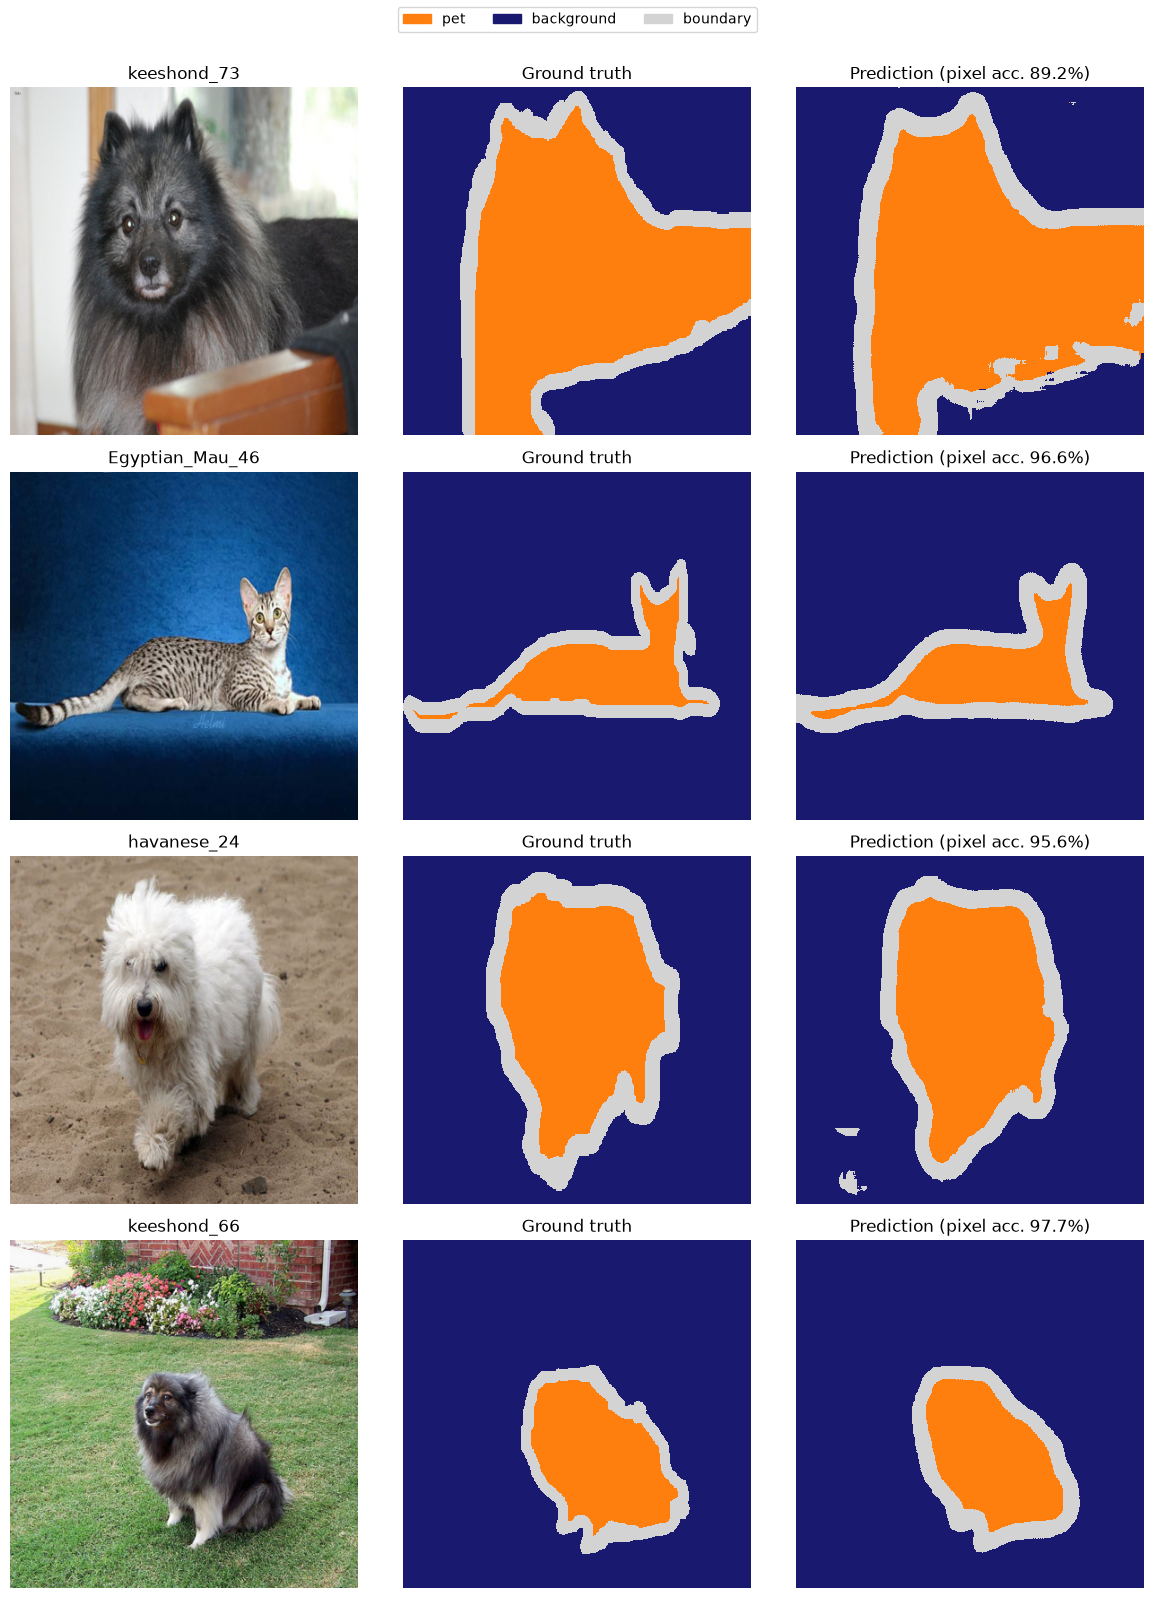

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# --- Load the model to test ---
ckpt = torch.load('checkpoints/v2-checkpoint-29.pt', map_location=device)
model = UNet().to(device)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

# --- Class colors: 0 = pet, 1 = background, 2 = boundary ---
class_names = ["pet", "background", "boundary"]
cmap = ListedColormap(["tab:orange", "midnightblue", "lightgray"])

n_samples = 4
margin = test_set.margin
indices = np.random.choice(len(test_set), n_samples, replace=False)

fig, axes = plt.subplots(n_samples, 3, figsize=(12, 4 * n_samples))
with torch.no_grad():
    for row, idx in enumerate(indices):
        x, y = test_set[idx]                                   # x: (3, 572, 572), y: (1, 388, 388)
        y = y.squeeze(0).long() - 1                            # (388, 388), classes {0, 1, 2}, making y fit in our class index

        logits = model(x.unsqueeze(0).to(device))              # (1, 3, 388, 388)
        pred = logits.argmax(dim=1).squeeze(0).cpu()           # (388, 388), Decision rule : most likely class per pixel

        img = x[:, margin:-margin, margin:-margin]             # remove the mirrored border -> (3, 388, 388)
        acc = (pred == y).float().mean().item()

        axes[row, 0].imshow(img.permute(1, 2, 0))              # (C, H, W) -> (H, W, C) for matplotlib
        axes[row, 0].set_title(test_set.names[idx])
        axes[row, 1].imshow(y, cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
        axes[row, 1].set_title("Ground truth")
        axes[row, 2].imshow(pred, cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
        axes[row, 2].set_title(f"Prediction (pixel acc. {acc:.1%})")

for ax in axes.flat:
    ax.axis("off")

fig.legend(handles=[Patch(color=cmap(i), label=name) for i, name in enumerate(class_names)],
           loc="upper center", ncol=3)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## Evaluation

In [ ]:
checkpoint = torch.load('checkpoints/v2-checkpoint-29.pt')

model = UNet()
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)

model.eval()

intersection = torch.zeros(3, device=device)
union = torch.zeros(3, device=device)
correct = 0
total = 0

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = (y.squeeze(1).long() - 1).to(device)
        pred = model(x).argmax(dim=1)

        # pixel accuracy
        correct += (pred == y).sum()
        total += y.numel()

        # IoU per class
        for c in range(3):
            intersection[c] += ((pred == c) & (y == c)).sum()
            union[c] += ((pred == c) | (y == c)).sum()

pixel_acc = correct / total
iou = intersection / union
print('Pixel accuracy:', pixel_acc.item())
print('IoU per class: ', iou.tolist())
print('Mean IoU:      ', iou.mean().item())

Pixel accuracy: 0.8859844207763672
IoU per class:  [0.7900015115737915, 0.8704864382743835, 0.5346843004226685]
Mean IoU:       0.7317241430282593
